# 4. Finite Metallic Back-Reflector & Lossless Substrate Invariant

## Physical Motivation & Learning Objectives
In scattering-matrix formalisms, **semi-infinite substrates and superstrates must be lossless** ($\operatorname{Im}(n) = 0$). This invariant ensures that propagating diffraction orders satisfy energy conservation and can be cleanly separated from evanescent decay.

In this tutorial:
1. We explain why metallic substrates cannot be semi-infinite in EMUstack.
2. We demonstrate how to correctly model an optically thick metallic mirror ($100$ nm Ag) backed by a lossless glass substrate.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import concurrent.futures

from EMUstack.backend import materials, objects, plotting
from EMUstack.backend.stack import Stack


## Structure Definition: Air / Absorber / Ag Mirror / Glass Substrate


In [2]:
wavelengths = np.linspace(400, 1000, 16)
period = 500.0  # nm

light_list = [objects.Light(wl, max_order_PWs=1, theta=0.0, phi=0.0) for wl in wavelengths]

superstrate = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air, loss=False)
active_film = objects.ThinFilm(period, height_nm=50.0, material=materials.Material(2.5 + 0.1j), loss=True)
silver_film = objects.ThinFilm(period, height_nm=100.0, material=materials.Ag, loss=True)
substrate   = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Material(1.5), loss=False)

def simulate_stack(light):
    sim_sup = superstrate.calc_modes(light)
    sim_act = active_film.calc_modes(light)
    sim_ag  = silver_film.calc_modes(light)
    sim_sub = substrate.calc_modes(light)
    
    stk = Stack((sim_sub, sim_ag, sim_act, sim_sup))
    stk.calc_scat(pol='TE')
    return stk

with concurrent.futures.ThreadPoolExecutor() as executor:
    stacks_list = list(executor.map(simulate_stack, light_list))


## Spectra Evaluation


<ipython-input-1-667545d58221>:2: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


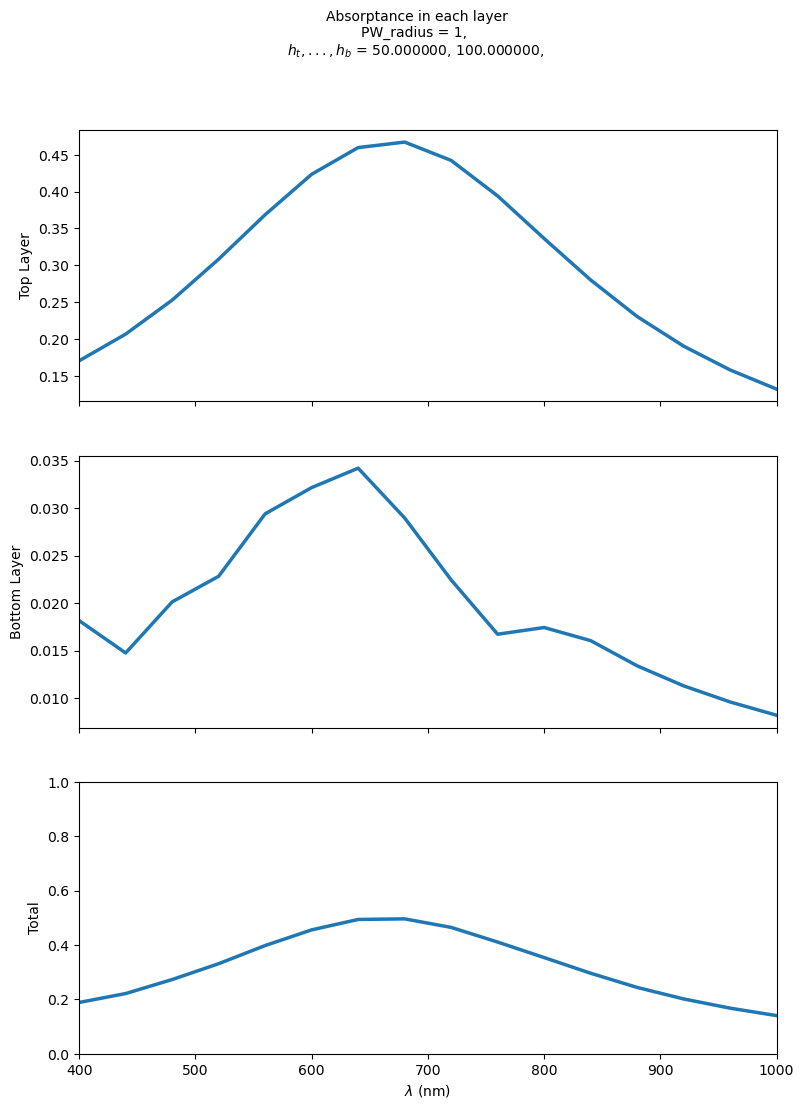

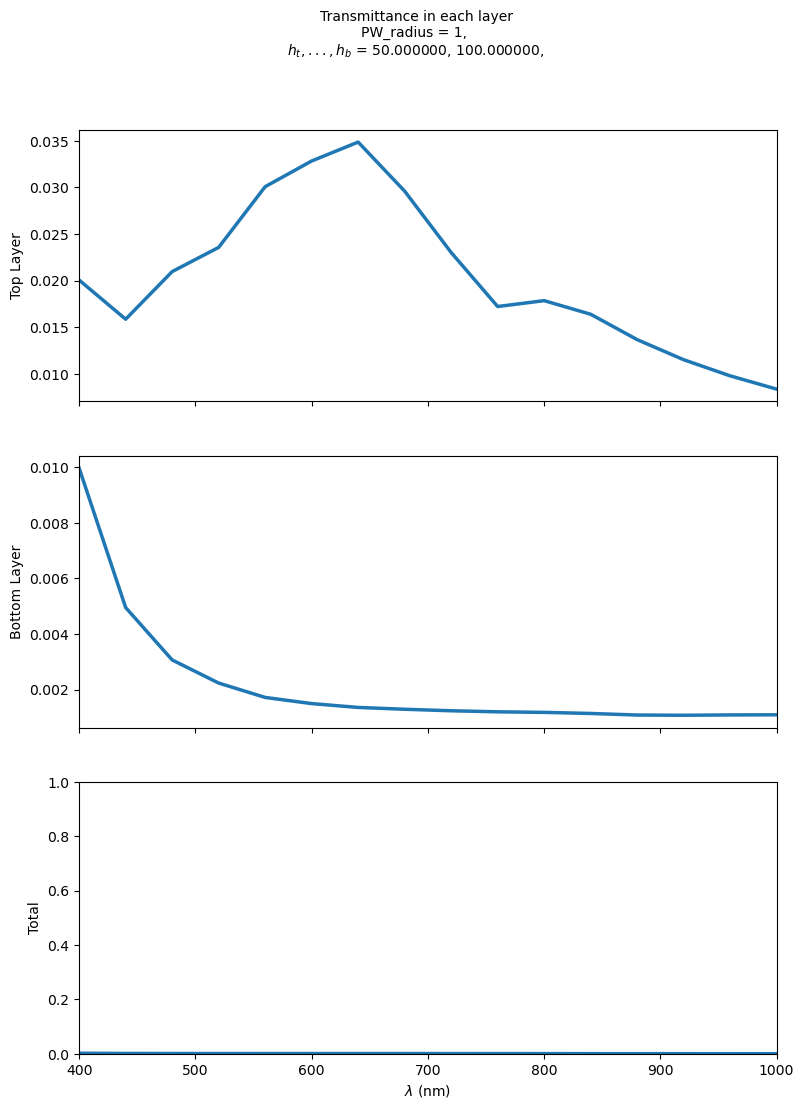

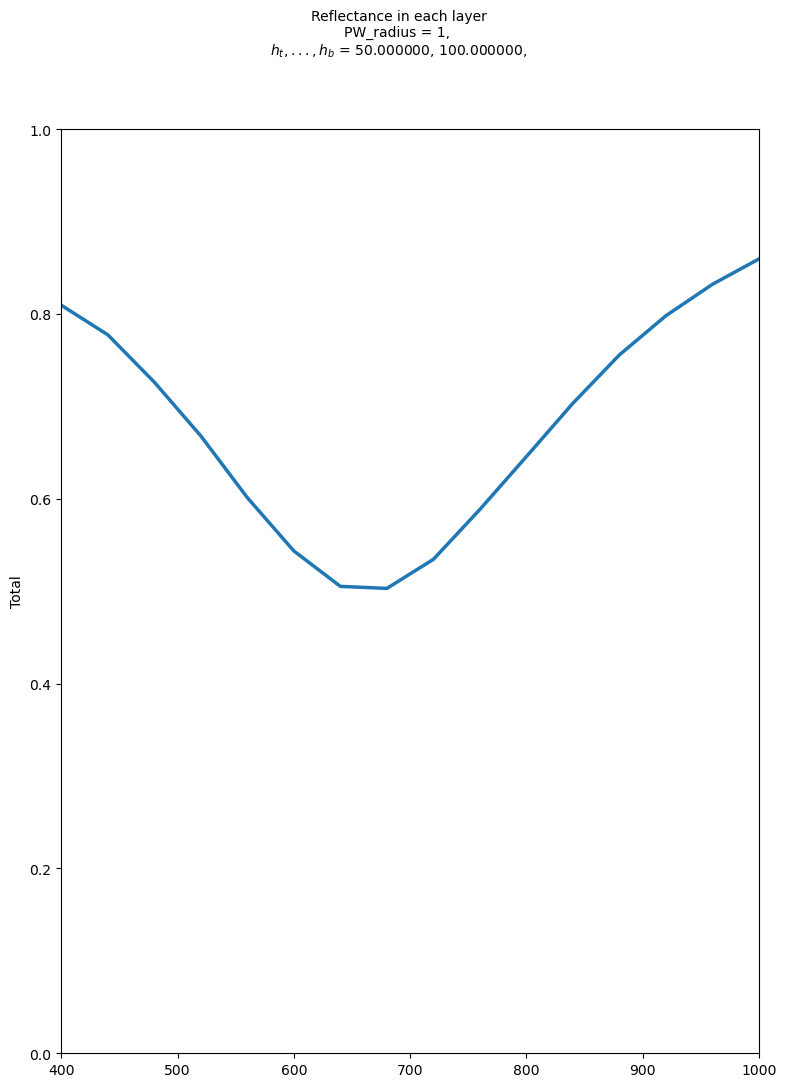

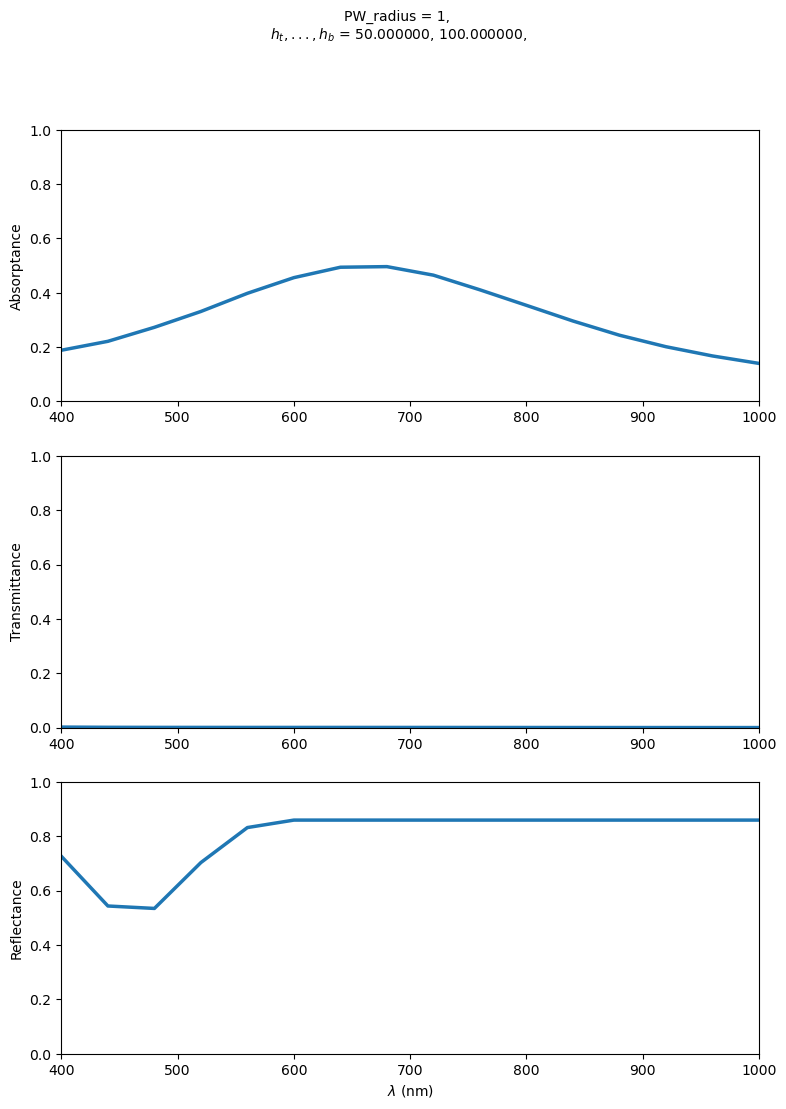

In [3]:
fig_tra = plotting.t_r_a_plots(stacks_list, plot_layers=True, save_pdf=False, save_txt=False)
plt.show()


## Physical Interpretation
- The $100$ nm silver layer acts as an opaque back-reflector with transmission $T \to 0$.
- Placing the metallic mirror above a lossless substrate satisfies the boundary condition invariant while capturing the optical physics of a mirrored substrate.
